# Seebeck dataset from Starrydata2: S, n, T plus other variables

Builds a model-ready table from the Starrydata thermoelectric project. Each row is one Seebeck point S(T) for a sample, with:

| Group | Columns | Use as input? |
|---|---|---|
| Target | `S_uVK` | target |
| Core measured | `T_K`, `log10_n_cm3` (same sample, matched within `TOL_K`) | yes |
| Other measured, same sample and T | `log10_sigma_Sm`, `log10_mu_cm2Vs` (reported or σ/(ne)), `kappa_WmK` | yes (partly missing) |
| Physics-derived | `S_SPB_abs_m1_uVK`, `eta_SPB_m1` (SPB with m* = 1 mₑ), `T_over_n23` | yes (target-free) |
| Composition | `el_<prop>_{mean,std,min,max,range}` for electronegativity, mass, radius, row, group, Mendeleev no., melting point, valence e⁻; `frac_<El>`; dopant counts | yes |
| Metadata | carrier type (Hall sign), composition system, form, fabrication, measurement methods, purity, density, grain size | categorical |
| **Computed from S** | `leak_PF`, `leak_ZT`, `leak_kappaL`, `leak_kappaE` | **never** (QC only) |

`feature_columns.json` lists these groups so you can pick features directly.

**Rules built in:** carrier type comes from the Hall sign, never from S. Questionable rows are **flagged, not dropped**. Split train/test on `study_id` (the paper) so each paper stays entirely in one set.

Runtime on Colab: about 2–3 min (most of it installing pymatgen).

## 0. Settings
Edit these, then **Runtime → Run all**.

In [1]:
TOL_K = 5.0              # max |T_S - T_n| (K) for matching, and the edge tolerance for interpolating other properties
EXPERIMENT_ONLY = False  # True -> keep only samples with DataType == 'Experiment'
FORCE_DOWNLOAD = False   # True -> re-download even if files exist
SAVE_TO_DRIVE = False    # True -> copy outputs to Google Drive (MyDrive/seebeck_dataset)

from pathlib import Path
DATA_DIR = Path("starrydata_raw")
OUT_DIR = Path("seebeck_dataset")

In [2]:
!pip -q install pymatgen pyarrow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.6/55.6 kB 2.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 825.8/825.8 kB 13.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.6/4.6 MB 32.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.6/62.6 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 332.3/332.3 kB 8.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.1/73.1 kB 2.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 962.5/962.5 kB 20.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.1/60.1 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 4.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires requests==2.32.4, but you have requests 2.3

In [3]:
import datetime as dt
import hashlib
import json
import re
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd

BASE_URL = "https://github.com/starrydata/starrydata_datasets/releases/latest/download/"
PROJECT = "ThermoelectricMaterials"
E_CHARGE = 1.602176634e-19  # C

## 1. Property names and units (S, n, R_H)
These are the Starrydata `prop_y` names that count as S, n and R_H, with the units accepted for each. Everything is converted to SI. Curves in other units are dropped **and counted** in the manifest.

In [4]:
# (prop_y name as it appears in Starrydata) -> canonical property.
# Units are checked separately; anything not listed in UNITS is dropped and counted.
PROP_ALIASES = {
    "Seebeck coefficient": "S",
    "thermopower": "S",
    "Thermopower": "S",
    "S": "S",
    "Carrier concentration": "n",
    "Hall coefficient": "RH",
}
UNITS = {  # accepted units -> multiplier to SI
    "S": {"V*K^(-1)": 1.0, "V/K": 1.0, "kg*m**2/A/s**3": 1.0},   # all equal V/K
    "n": {"m^(-3)": 1.0, "m**(-3)": 1.0, "1/m**3": 1.0},
    "RH": {"m^3*C^(-1)": 1.0, "m**3/C": 1.0, "m**3/(A*s)": 1.0},
}
# x-axis -> temperature in K
def x_to_kelvin(prop_x: str, unit_x: str, x: np.ndarray) -> np.ndarray | None:
    if prop_x in ("Temperature", "T") and unit_x == "K":
        return x
    if prop_x == "Inverse temperature" and unit_x == "K^(-1)":
        with np.errstate(divide="ignore"):
            return 1.0 / x
    return None  # Pisarenko plots (x = carrier conc.) etc. are not used here

## 2. Composition parsing and composition systems
Labels are based on the formula only (not confirmed crystal structure). **The first matching rule wins**, so each sample gets one label that can be used as a group. `MAIN_FRAC` ignores dopants below 5 at.%. Edit `SYSTEM_RULES` to fit your thesis families.

In [5]:
# First match wins -> an EXCLUSIVE label usable as a grouping variable.
# "main" = elements with atomic fraction >= MAIN_FRAC (dopants ignored).
# Edit these rules to match your thesis definitions; they are formula-based only,
# NOT confirmed crystal structure.
MAIN_FRAC = 0.05
CHALC = {"S", "Se", "Te"}

def _ratio(c, a, b):
    return c.get(a, 0) / c[b] if c.get(b) else np.inf

SYSTEM_RULES = [
    ("Bi-Sb-Te-Se", lambda m, c: m <= {"Bi", "Sb", "Te", "Se"} and m & {"Bi", "Sb"} and m & {"Te", "Se"}),
    ("Ge-Te",       lambda m, c: "Ge" in m and "Te" in m and m <= {"Ge", "Te", "Sb", "Bi", "Pb", "Sn", "Se"}),
    ("Pb chalcogenide", lambda m, c: "Pb" in m and m & CHALC and m <= {"Pb", "Sn", "S", "Se", "Te"}),
    ("Sn chalcogenide", lambda m, c: "Sn" in m and m & CHALC and m <= {"Sn", "Ge", "S", "Se", "Te"}),
    ("Cu/Ag chalcogenide", lambda m, c: m & {"Cu", "Ag"} and m & CHALC and m <= {"Cu", "Ag", "S", "Se", "Te"}),
    ("Mg-Sb-Bi",    lambda m, c: "Mg" in m and m & {"Sb", "Bi"} and m <= {"Mg", "Sb", "Bi", "Te", "Se"}),
    ("Mg-Si-Sn-Ge", lambda m, c: "Mg" in m and m & {"Si", "Sn", "Ge"} and m <= {"Mg", "Si", "Sn", "Ge"}),
    ("Si-Ge",       lambda m, c: m & {"Si", "Ge"} and m <= {"Si", "Ge"}),
    ("Zn-O",        lambda m, c: m == {"Zn", "O"}),
    ("Sr-Ti-O",     lambda m, c: {"Sr", "Ti", "O"} <= m and m <= {"Sr", "Ti", "O", "La", "Nb", "Ba", "Ca"}),
    ("Skutterudite-compatible TM-Pn 1:3",
     lambda m, c: any(2.4 <= (c.get("Sb", 0) + c.get("As", 0) + c.get("P", 0)) / c[t] <= 3.6
                      for t in ("Co", "Rh", "Ir", "Fe", "Ni") if t in c)),
    ("Half-Heusler-compatible 1:1:1",
     lambda m, c: len(m) == 3 and all(0.25 <= c[e] <= 0.42 for e in m)),
]

_TOKEN = re.compile(r"([A-Z][a-z]?)(\d*\.?\d*)|(\()|(\))(\d*\.?\d*)")

def parse_formula(formula: str) -> dict[str, float] | None:
    """Parse e.g. 'Pb1Te1.01Na0.02', 'Bi0.5Sb1.5Te3', '(Bi2Te3)0.9(Sb2Te3)0.1'.
    Returns normalized atomic fractions or None if unparseable."""
    if not isinstance(formula, str) or not formula.strip():
        return None
    s = re.sub(r"[\s\-·•]", "", formula)
    stack = [{}]
    pos = 0
    for m in _TOKEN.finditer(s):
        if m.start() != pos:  # unparsed characters -> give up rather than guess
            return None
        pos = m.end()
        el, num, lpar, rpar, rnum = m.groups()
        if el:
            stack[-1][el] = stack[-1].get(el, 0) + (float(num) if num else 1.0)
        elif lpar:
            stack.append({})
        elif rpar:
            if len(stack) == 1:
                return None
            grp = stack.pop()
            k = float(rnum) if rnum else 1.0
            for e, v in grp.items():
                stack[-1][e] = stack[-1].get(e, 0) + v * k
    if pos != len(s) or len(stack) != 1 or not stack[0]:
        return None
    tot = sum(stack[0].values())
    if tot <= 0:
        return None
    return {e: v / tot for e, v in stack[0].items() if v > 0}

def assign_system(frac: dict | None) -> str:
    if not frac:
        return "unparsed"
    main = {e for e, f in frac.items() if f >= MAIN_FRAC}
    for name, rule in SYSTEM_RULES:
        try:
            if rule(main, frac):
                return name
        except (KeyError, ZeroDivisionError):
            continue
    return "Other"

## 3. Download helpers

In [6]:
def fetch(data_dir: Path, force: bool) -> dict[str, Path]:
    data_dir.mkdir(parents=True, exist_ok=True)
    paths = {}
    for kind in ("papers", "samples", "curves"):
        fn = f"{PROJECT}_{kind}.csv.gz"
        p = data_dir / fn
        if force or not p.exists():
            print(f"downloading {fn} ...")
            urllib.request.urlretrieve(BASE_URL + fn, p)
        paths[kind] = p
    return paths

def sha256(p: Path) -> str:
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

## 4. Core functions: points, carrier type, S–n matching
- **Negative R_H → n (high confidence).** A positive R_H may be a digitized *magnitude* (seen for Ce-filled CoSb₃ and Bi₂Se₃), so p labels are marked `low_check_source`.
- n comes from the reported carrier concentration if available, otherwise 1/(e|R_H|) (assumes Hall factor = 1).
- S and n are paired with `merge_asof` at the nearest temperature within `TOL_K`.

In [7]:
def explode_curves(curves: pd.DataFrame, log: dict) -> pd.DataFrame:
    """One row per digitized point for S, n, RH vs temperature."""
    curves = curves.copy()
    curves["prop"] = curves["prop_y"].map(PROP_ALIASES)
    curves = curves[curves["prop"].notna()]
    rows, dropped = [], {"bad_unit_y": 0, "bad_x_axis": 0, "bad_json": 0, "len_mismatch": 0}
    for r in curves.itertuples(index=False):
        mult = UNITS[r.prop].get(r.unit_y)
        if mult is None:
            dropped["bad_unit_y"] += 1
            continue
        try:
            x = np.asarray(json.loads(r.x), dtype=float)
            y = np.asarray(json.loads(r.y), dtype=float) * mult
        except (TypeError, ValueError):
            dropped["bad_json"] += 1
            continue
        if x.shape != y.shape:
            dropped["len_mismatch"] += 1
            continue
        T = x_to_kelvin(r.prop_x, r.unit_x, x)
        if T is None:
            dropped["bad_x_axis"] += 1
            continue
        ok = np.isfinite(T) & np.isfinite(y)
        rows.append(pd.DataFrame({
            "SID": r.SID, "sample_id": r.sample_id, "figure_id": r.figure_id,
            "figure_name": r.figure_name, "prop": r.prop, "T_K": T[ok], "value": y[ok],
        }))
    log["curves_dropped"] = dropped
    pts = pd.concat(rows, ignore_index=True)
    before = len(pts)
    # identical points digitized twice (same sample, prop, T, value) -> keep one
    key = pts.assign(_T=pts["T_K"].round(1), _v=pts["value"].round(12))
    pts = pts[~key.duplicated(["SID", "sample_id", "prop", "_T", "_v"])]
    log["duplicate_points_removed"] = before - len(pts)
    log["points_by_prop"] = pts["prop"].value_counts().to_dict()
    return pts

def carrier_type_from_hall(pts: pd.DataFrame) -> pd.DataFrame:
    """Target-free carrier type: sign of Hall coefficient only. Never uses Seebeck."""
    rh = pts[pts["prop"] == "RH"]
    g = rh.groupby(["SID", "sample_id"])["value"]
    out = pd.DataFrame({"n_neg": g.apply(lambda v: (v < 0).sum()),
                        "n_pos": g.apply(lambda v: (v > 0).sum())}).reset_index()
    out["carrier_type"] = np.select(
        [(out.n_neg > 0) & (out.n_pos == 0), (out.n_pos > 0) & (out.n_neg == 0)],
        ["n", "p"], default="sign-changing")
    out["carrier_type_source"] = "hall_sign"
    # A negative R_H was deliberately plotted -> reliable n. A positive R_H may just be a
    # digitized MAGNITUDE (seen in real data: Ce-filled CoSb3, Bi2Se3 labelled 'p').
    # So 'p' needs verification against the paper text before use.
    out["carrier_type_confidence"] = np.select(
        [out.carrier_type == "n", out.carrier_type == "p"], ["high", "low_check_source"], default="n/a")
    return out[["SID", "sample_id", "carrier_type", "carrier_type_source", "carrier_type_confidence"]]

def carrier_density_points(pts: pd.DataFrame) -> pd.DataFrame:
    """n(T) per sample. Prefer reported carrier concentration; fall back to 1/(e|RH|)
    (Hall factor r_H = 1 assumed -> recorded in n_source)."""
    conc = pts[pts["prop"] == "n"].assign(n_m3=lambda d: d["value"].abs(), n_source="reported_n")
    hall = pts[pts["prop"] == "RH"]
    hall = hall[hall["value"] != 0].assign(
        n_m3=lambda d: 1.0 / (E_CHARGE * d["value"].abs()), n_source="hall_1/(e|RH|)")
    have_conc = set(map(tuple, conc[["SID", "sample_id"]].drop_duplicates().values))
    hall = hall[[(a, b) not in have_conc for a, b in zip(hall["SID"], hall["sample_id"])]]
    n = pd.concat([conc, hall], ignore_index=True)
    n["n_reported_sign"] = np.sign(n["value"])  # kept for QC only; conventions vary
    return n.rename(columns={"figure_id": "n_figure_id", "T_K": "T_n_K"})[
        ["SID", "sample_id", "n_figure_id", "T_n_K", "n_m3", "n_source", "n_reported_sign"]]

def match_s_to_n(pts: pd.DataFrame, n: pd.DataFrame, tol_k: float) -> pd.DataFrame:
    S = pts[pts["prop"] == "S"].rename(columns={"value": "S_VK", "figure_id": "S_figure_id"})
    S = S[["SID", "sample_id", "S_figure_id", "figure_name", "T_K", "S_VK"]]
    S["key"] = S["SID"].astype(str) + "_" + S["sample_id"].astype(str)
    n = n.assign(key=n["SID"].astype(str) + "_" + n["sample_id"].astype(str))
    S = S[S["key"].isin(set(n["key"]))].sort_values("T_K")
    n = n.sort_values("T_n_K")
    m = pd.merge_asof(S, n.drop(columns=["SID", "sample_id"]), left_on="T_K", right_on="T_n_K",
                      by="key", direction="nearest", tolerance=tol_k)
    m = m[m["n_m3"].notna()].drop(columns="key")
    m["dT_K"] = (m["T_K"] - m["T_n_K"]).abs()
    return m


def parse_sample_info(s: str) -> dict:
    try:
        d = json.loads(s) if isinstance(s, str) else {}
    except ValueError:
        d = {}
    get = lambda k: ((d.get(k) or {}).get("category") or "").strip() or None
    return {"data_type": get("DataType"), "form": get("Form"),
            "material_family_meta": get("MaterialFamily"),
            "electrical_measurement": get("ElectricalMeasurement"),
            "thermal_measurement": get("ThermalMeasurement"),
            "fabrication": get("FabricationProcess"),
            "purity": get("Purity"),
            "relative_density_cat": get("RelativeDensity"),
            "grain_size_cat": get("GrainSize")}

## 5. Other measured properties of the same sample
σ (or 1/ρ), mobility and κ are **interpolated to each Seebeck temperature**, only within the range each property was measured (no extrapolation). σ and μ are interpolated in log space.

Power factor, ZT, κ_e and κ_L are all computed from S (κ_e uses a Lorenz number that depends on S), so they get a `leak_` prefix. They're kept for QC only; **don't use them as inputs**.

In [8]:
# Other properties measured on the SAME sample, interpolated to each Seebeck temperature.
# (canonical name, {unit: converter to SI}, interpolate in log space?)
#   FEATURE-SAFE: measured independently of S.
#   leak_*: computed FROM S (PF = S^2*sigma, ZT, kappa_e via L(S), kappa_L = kappa - kappa_e).
#           Kept only for QC; never use them as model inputs.
AUX_PROPS = {
    "Electrical conductivity":      ("sigma_Sm", {"ohm^(-1)*m^(-1)": lambda v: v, "S/m": lambda v: v}, True),
    "Electrical resistivity":       ("sigma_Sm", {"ohm*m": lambda v: 1.0 / v}, True),
    "Carrier mobility":             ("mu_m2Vs", {"m^2*V^(-1)*s^(-1)": lambda v: v, "A*s**2/kg": lambda v: v}, True),
    "Hall mobility":                ("mu_m2Vs", {"m^2*V^(-1)*s^(-1)": lambda v: v, "A*s**2/kg": lambda v: v}, True),
    "Mobility":                     ("mu_m2Vs", {"m^2*V^(-1)*s^(-1)": lambda v: v, "A*s**2/kg": lambda v: v}, True),
    "Thermal conductivity":         ("kappa_WmK", {"W*m^(-1)*K^(-1)": lambda v: v}, False),
    "total thermal conductivity":   ("kappa_WmK", {"W*m^(-1)*K^(-1)": lambda v: v}, False),
    "Power factor":                 ("leak_PF_WmK2", {"W*m^(-1)*K^(-2)": lambda v: v}, False),
    "ZT":                           ("leak_ZT", {"-": lambda v: v}, False),
    "Lattice thermal conductivity": ("leak_kappaL_WmK", {"W*m^(-1)*K^(-1)": lambda v: v}, False),
    "Electronic thermal conductivity": ("leak_kappaE_WmK", {"W*m^(-1)*K^(-1)": lambda v: v}, False),
    "electron thermal conductivity":   ("leak_kappaE_WmK", {"W*m^(-1)*K^(-1)": lambda v: v}, False),
    "Carrier thermal conductivity":    ("leak_kappaE_WmK", {"W*m^(-1)*K^(-1)": lambda v: v}, False),
}

def explode_aux(curves: pd.DataFrame, keys: set) -> pd.DataFrame:
    c = curves[curves["prop_y"].isin(AUX_PROPS)]
    c = c[[(a, b) in keys for a, b in zip(c["SID"], c["sample_id"])]]
    rows = []
    for r in c.itertuples(index=False):
        canon, units, _ = AUX_PROPS[r.prop_y]
        conv = units.get(r.unit_y)
        if conv is None:
            continue
        try:
            x = np.asarray(json.loads(r.x), dtype=float)
            y = np.asarray(json.loads(r.y), dtype=float)
        except (TypeError, ValueError):
            continue
        T = x_to_kelvin(r.prop_x, r.unit_x, x) if x.shape == y.shape else None
        if T is None:
            continue
        with np.errstate(divide="ignore", invalid="ignore"):
            v = conv(y)
        ok = np.isfinite(T) & np.isfinite(v)
        rows.append(pd.DataFrame({"SID": r.SID, "sample_id": r.sample_id, "prop": canon,
                                  "T_K": T[ok], "value": v[ok]}))
    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame(
        columns=["SID", "sample_id", "prop", "T_K", "value"])

def attach_aux(m: pd.DataFrame, aux: pd.DataFrame, tol_k: float) -> pd.DataFrame:
    """Linear interpolation (log-linear for sigma, mu) at each Seebeck T, only INSIDE the
    measured T range of that property (+/- tol_k at the ends). No extrapolation."""
    logspace = {canon: lg for canon, _, lg in AUX_PROPS.values()}
    m = m.copy()
    for canon in sorted(aux["prop"].unique()):
        m[canon] = np.nan
        a = aux[aux["prop"] == canon]
        if logspace[canon]:
            a = a[a["value"] > 0]
        for (sid, smp), g in a.groupby(["SID", "sample_id"]):
            idx = m.index[(m["SID"] == sid) & (m["sample_id"] == smp)]
            if len(idx) == 0:
                continue
            g = g.groupby("T_K", as_index=False)["value"].mean().sort_values("T_K")
            Tq = m.loc[idx, "T_K"].to_numpy()
            yv = np.log(g["value"].to_numpy()) if logspace[canon] else g["value"].to_numpy()
            out = np.interp(Tq, g["T_K"].to_numpy(), yv)
            inside = (Tq >= g["T_K"].min() - tol_k) & (Tq <= g["T_K"].max() + tol_k)
            out = np.where(inside, np.exp(out) if logspace[canon] else out, np.nan)
            m.loc[idx, canon] = out
    return m

## 6. Composition descriptors
Fraction-weighted mean, std, min, max and range of elemental properties from pymatgen, plus element fractions and dopant counts. These cover the kind of electronegativity descriptors used in the SISSO paper without committing to its printed equation.

In [9]:
# Fraction-weighted statistics of elemental properties (Magpie-style), from pymatgen.
ELEM_PROPS = ["X", "atomic_mass", "atomic_radius", "row", "group", "mendeleev_no",
              "melting_point", "n_valence"]

def _n_valence(el) -> float:
    g = el.group
    if el.block == "f":
        return np.nan
    return float(g if g <= 12 else g - 10)

def element_table(elements) -> pd.DataFrame:
    from pymatgen.core import Element
    rows = {}
    for e in elements:
        try:
            el = Element(e)
        except Exception:
            continue
        rec = {}
        for p in ELEM_PROPS:
            try:
                v = _n_valence(el) if p == "n_valence" else getattr(el, p)
                rec[p] = float(v) if v is not None else np.nan
            except Exception:
                rec[p] = np.nan
        rows[e] = rec
    return pd.DataFrame.from_dict(rows, orient="index")

def composition_descriptors(comp_cache: dict) -> pd.DataFrame:
    """One row per composition string: n_elements, dopant stats, element fractions (frac_*),
    and weighted mean / std / min / max / range of each elemental property (el_*)."""
    comps = {c: f for c, f in comp_cache.items() if f}
    all_el = sorted({e for f in comps.values() for e in f})
    try:
        tab = element_table(all_el)
    except ImportError:
        print("pymatgen not installed -> skipping elemental-property descriptors")
        tab = pd.DataFrame(index=all_el, columns=ELEM_PROPS, dtype=float)
    recs = []
    for c, f in comps.items():
        r = {"composition": c, "n_elements": len(f),
             "n_dopants": sum(v < MAIN_FRAC for v in f.values()),
             "dopant_total_frac": sum(v for v in f.values() if v < MAIN_FRAC)}
        r.update({f"frac_{e}": v for e, v in f.items()})
        for p in ELEM_PROPS:
            vals = np.array([tab.at[e, p] if e in tab.index else np.nan for e in f], float)
            w = np.array(list(f.values()), float)
            ok = np.isfinite(vals)
            if ok.sum() == 0 or w[ok].sum() < 0.9:     # >10% of atoms lack the property -> NaN
                r.update({f"el_{p}_{s}": np.nan for s in ("mean", "std", "min", "max", "range")})
                continue
            v, ww = vals[ok], w[ok] / w[ok].sum()
            mu = (ww * v).sum()
            r.update({f"el_{p}_mean": mu, f"el_{p}_std": np.sqrt((ww * (v - mu) ** 2).sum()),
                      f"el_{p}_min": v.min(), f"el_{p}_max": v.max(), f"el_{p}_range": v.max() - v.min()})
        recs.append(r)
    d = pd.DataFrame(recs)
    frac_cols = [c for c in d.columns if c.startswith("frac_")]
    d[frac_cols] = d[frac_cols].fillna(0.0)
    return d

## 7. SPB baseline (target-free)
Single parabolic band with acoustic-phonon scattering and Hall factor = 1, computed from **n and T only** with m* = 1 mₑ. It is the baseline for the residual ΔS = S − S_SPB. For the thesis, fit m* **inside each training fold** and recompute with `spb_seebeck_abs(n, T, m_star)`.

In [10]:
# Single parabolic band, acoustic-phonon scattering (lambda = 0), Hall factor = 1:
#   n = 4*pi*(2 m* kB T / h^2)^(3/2) * F_1/2(eta)
#   |S| = (kB/e) * (2 F_1(eta) / F_0(eta) - eta)
# Uses only n, T and an ASSUMED m*; never the measured S. Default m* = 1 m_e.
# In the thesis, calibrate m* on TRAINING data only and recompute with spb_seebeck_abs().
KB, H_PL, M_E = 1.380649e-23, 6.62607015e-34, 9.1093837015e-31

def _fermi_table():
    from scipy.integrate import quad
    from scipy.special import expit
    etas = np.linspace(-30, 120, 3001)
    def F(j, eta):
        upper = max(eta, 0) + 60
        return quad(lambda x: x ** j * expit(eta - x), 0, upper, limit=200)[0]
    F12 = np.array([F(0.5, e) for e in etas])
    F1 = np.array([F(1.0, e) for e in etas])
    F0 = np.logaddexp(0, etas)
    return etas, F12, F1, F0

_FT = None
def spb_seebeck_abs(n_m3, T_K, m_star=1.0):
    """Returns (|S_SPB| in V/K, reduced Fermi level eta). NaN outside the tabulated eta range."""
    global _FT
    if _FT is None:
        _FT = _fermi_table()
    etas, F12, F1, F0 = _FT
    n_m3, T_K = np.asarray(n_m3, float), np.asarray(T_K, float)
    Nc = 4 * np.pi * (2 * m_star * M_E * KB * T_K / H_PL ** 2) ** 1.5
    target = np.log(n_m3 / Nc)
    eta = np.interp(target, np.log(F12), etas, left=np.nan, right=np.nan)
    S = (KB / E_CHARGE) * (2 * np.interp(eta, etas, F1) / np.interp(eta, etas, F0) - eta)
    return S, eta

## 8. Download and load

In [11]:
log: dict = {"run_utc": dt.datetime.utcnow().isoformat(timespec="seconds") + "Z",
             "tol_k": TOL_K, "experiment_only": EXPERIMENT_ONLY,
             "main_frac_for_systems": MAIN_FRAC}
paths = fetch(DATA_DIR, FORCE_DOWNLOAD)
log["inputs"] = {k: {"file": str(p), "sha256": sha256(p)} for k, p in paths.items()}

curves = pd.read_csv(paths["curves"], low_memory=False)
samples = pd.read_csv(paths["samples"], low_memory=False)
papers = pd.read_csv(paths["papers"], low_memory=False, usecols=["SID", "DOI", "issued"])
log["raw_rows"] = {"curves": len(curves), "samples": len(samples), "papers": len(papers)}

pts = explode_curves(curves, log)
ctype = carrier_type_from_hall(pts)
n = carrier_density_points(pts)
m = match_s_to_n(pts, n, TOL_K)

/tmp/ipykernel_2663/4070529955.py:1: DeprecationWarning: datetime.datetime.utcnow() is deprecated and scheduled for removal in a future version. Use timezone-aware objects to represent datetimes in UTC: datetime.datetime.now(datetime.UTC).
  log: dict = {"run_utc": dt.datetime.utcnow().isoformat(timespec="seconds") + "Z",


downloading ThermoelectricMaterials_papers.csv.gz ...
downloading ThermoelectricMaterials_samples.csv.gz ...
downloading ThermoelectricMaterials_curves.csv.gz ...


## 9. Match S to n; attach metadata, carrier type, DOI and composition system

In [12]:
# sample metadata
meta = pd.DataFrame([parse_sample_info(v) for v in samples["sample_info"]])
samples = pd.concat([samples[["SID", "sample_id", "sample_name", "composition"]], meta], axis=1)
samples = samples.drop_duplicates(["SID", "sample_id"])
m = m.merge(samples, on=["SID", "sample_id"], how="left")
m = m.merge(ctype, on=["SID", "sample_id"], how="left")
m["carrier_type"] = m["carrier_type"].fillna("unknown")
m["carrier_type_source"] = m["carrier_type_source"].fillna("none")
m["carrier_type_confidence"] = m["carrier_type_confidence"].fillna("n/a")
m = m.merge(papers[["SID", "DOI"]], on="SID", how="left")

# composition
comp_cache = {c: parse_formula(c) for c in m["composition"].dropna().unique()}
m["elem_frac_json"] = m["composition"].map(lambda c: json.dumps(comp_cache.get(c)) if comp_cache.get(c) else None)
m["comp_system"] = m["composition"].map(lambda c: assign_system(comp_cache.get(c)))

# units convenient for modelling
m["S_uVK"] = m["S_VK"] * 1e6
m["n_cm3"] = m["n_m3"] * 1e-6
m["log10_n_cm3"] = np.log10(m["n_cm3"])

## 10. Attach the other measured properties and derived physics features

In [13]:
# ---- other measured properties of the same sample at the same T
keys = set(zip(m["SID"], m["sample_id"]))
aux = explode_aux(curves, keys)
m = attach_aux(m.reset_index(drop=True), aux, TOL_K)
for c in ("sigma_Sm", "mu_m2Vs", "kappa_WmK", "leak_PF_WmK2", "leak_ZT", "leak_kappaL_WmK", "leak_kappaE_WmK"):
    if c not in m:
        m[c] = np.nan
# mobility: reported if available, else sigma/(n e)
mu_derived = m["sigma_Sm"] / (m["n_m3"] * E_CHARGE)
m = m.copy()
m["mu_source"] = np.where(m["mu_m2Vs"].notna(), "reported", np.where(mu_derived.notna(), "sigma/(n e)", "none"))
m["mu_cm2Vs"] = m["mu_m2Vs"].fillna(mu_derived) * 1e4
m["mu_reported_over_derived"] = m["mu_m2Vs"] / mu_derived   # ~1 if n, sigma, mu are consistent
# target-free physics features
m["log10_sigma_Sm"] = np.log10(m["sigma_Sm"])
m["log10_mu_cm2Vs"] = np.log10(m["mu_cm2Vs"])
m["T_over_n23"] = m["T_K"] / (m["n_cm3"] / 1e19) ** (2 / 3)   # degenerate SPB: S ~ m* T / n^(2/3)

## 11. SPB baseline column

In [14]:
# ---- SPB baseline with m* = 1 m_e (target-free; recalibrate m* inside training folds)
S_spb, eta = spb_seebeck_abs(m["n_m3"], m["T_K"], m_star=1.0)
m["S_SPB_abs_m1_uVK"] = S_spb * 1e6
m["eta_SPB_m1"] = eta

/tmp/ipykernel_2663/1541362847.py:29: RuntimeWarning: divide by zero encountered in divide
  target = np.log(n_m3 / Nc)


## 12. Composition descriptors

In [15]:
# ---- composition descriptors
desc = composition_descriptors(comp_cache)
m = m.merge(desc, on="composition", how="left").copy()

## 13. QC flags
`True` means a possible problem. Nothing is filtered here. `flag_hall_seebeck_sign_mismatch` and `flag_pf_sigma_S_inconsistent` use S and are **for checking only**. Ranges: |S| ≤ 1500 µV/K, n 1e16–1e23 cm⁻³, σ 1e-2–1e8 S/m, κ 0.05–500 W/mK. Mobility is flagged if the reported value differs from σ/(ne) by more than 3×.

In [16]:
# ---- QC flags (True = problem). Decide filters downstream; don't hide them.
m["flag_not_experiment"] = m["data_type"].ne("Experiment")
m["flag_not_bulk"] = ~m["form"].isin(["Bulk", "Polycrystal", "SingleCrystal", "OrientedBulk", "pellets", "disk"])
m["flag_S_range"] = m["S_uVK"].abs() > 1500
m["flag_n_range"] = ~m["n_cm3"].between(1e16, 1e23)
m["flag_T_range"] = ~m["T_K"].between(2, 1500)
# Hall sign vs Seebeck sign: QC ONLY. Do not use S to create labels/inputs (circularity).
sgn_expected = m["carrier_type"].map({"n": -1, "p": 1})
m["flag_hall_seebeck_sign_mismatch"] = sgn_expected.notna() & (np.sign(m["S_VK"]) != sgn_expected)
m["flag_hall_derived_n"] = m["n_source"].str.startswith("hall")
n_s_curves = m.groupby(["SID", "sample_id"])["S_figure_id"].transform("nunique")
m["flag_multiple_S_curves"] = n_s_curves > 1
# QC ONLY (uses S): sqrt(PF/sigma) should equal |S| if PF, sigma, S were digitized consistently
s_from_pf = np.sqrt(m["leak_PF_WmK2"] / m["sigma_Sm"])
m["flag_pf_sigma_S_inconsistent"] = (s_from_pf / m["S_VK"].abs() - 1).abs() > 0.3
m["flag_sigma_range"] = m["sigma_Sm"].notna() & ~m["sigma_Sm"].between(1e-2, 1e8)
m["flag_kappa_range"] = m["kappa_WmK"].notna() & ~m["kappa_WmK"].between(0.05, 500)
m["flag_mu_inconsistent"] = ~m["mu_reported_over_derived"].between(0.33, 3.0) & m["mu_reported_over_derived"].notna()
flag_cols = [c for c in m.columns if c.startswith("flag_")]
m["n_flags"] = m[flag_cols].sum(axis=1)

/usr/local/lib/python3.13/dist-packages/pandas/core/arraylike.py:399: RuntimeWarning: invalid value encountered in sqrt
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [17]:
if EXPERIMENT_ONLY:
    m = m[~m["flag_not_experiment"]]

# ids for grouped (study-held-out) splits
m["study_id"] = m["SID"]                                   # split on this
m["sample_key"] = m["SID"].astype(str) + "_" + m["sample_id"].astype(str)
m = m.sort_values(["SID", "sample_id", "S_figure_id", "T_K"]).reset_index(drop=True).copy()
m.insert(0, "point_id", np.arange(len(m)))

cols = ["point_id", "study_id", "sample_key", "SID", "DOI", "sample_id", "sample_name",
        "composition", "comp_system", "material_family_meta", "carrier_type", "carrier_type_source",
        "carrier_type_confidence", "T_K", "S_VK", "S_uVK", "n_m3", "n_cm3", "log10_n_cm3", "n_source", "T_n_K", "dT_K",
        "n_reported_sign", "S_figure_id", "figure_name", "n_figure_id",
        "data_type", "form", "electrical_measurement", "thermal_measurement", "fabrication",
        "purity", "relative_density_cat", "grain_size_cat", "elem_frac_json",
        # measured co-variables + derived physics features
        "sigma_Sm", "log10_sigma_Sm", "mu_cm2Vs", "log10_mu_cm2Vs", "mu_source",
        "mu_reported_over_derived", "kappa_WmK", "T_over_n23", "S_SPB_abs_m1_uVK", "eta_SPB_m1",
        # composition descriptors
        *[c for c in desc.columns if c != "composition"],
        # S-derived -> NOT features
        "leak_PF_WmK2", "leak_ZT", "leak_kappaL_WmK", "leak_kappaE_WmK",
        *flag_cols, "n_flags"]
m = m[cols]

# which columns may be used as model inputs (target-free) and which must not
feature_groups = {
    "target": ["S_uVK"],
    "measured_core": ["T_K", "log10_n_cm3"],
    "measured_extra": ["log10_sigma_Sm", "log10_mu_cm2Vs", "kappa_WmK"],
    "physics_derived": ["T_over_n23", "S_SPB_abs_m1_uVK", "eta_SPB_m1"],
    "composition": [c for c in desc.columns if c.startswith(("el_", "n_elements", "n_dopants", "dopant_"))],
    "element_fractions": [c for c in desc.columns if c.startswith("frac_")],
    "categorical_metadata": ["carrier_type", "comp_system", "material_family_meta", "form", "fabrication",
                             "electrical_measurement", "thermal_measurement", "purity",
                             "relative_density_cat", "grain_size_cat"],
    "group_ids_for_splitting": ["study_id", "sample_key"],
    "DO_NOT_USE_as_inputs_derived_from_S": ["leak_PF_WmK2", "leak_ZT", "leak_kappaL_WmK", "leak_kappaE_WmK",
                                            "flag_hall_seebeck_sign_mismatch", "flag_pf_sigma_S_inconsistent"],
}
coverage = {c: round(float(m[c].notna().mean()), 3) for c in
            feature_groups["measured_extra"] + feature_groups["physics_derived"] + ["el_X_mean"]}
feature_groups["_non_missing_fraction"] = coverage

## 14. Write outputs
`clean` = rows with no flags (having several S curves for one sample is allowed).

In [18]:
# ---- outputs
OUT_DIR.mkdir(parents=True, exist_ok=True)
m.to_csv(OUT_DIR / "matched_points.csv", index=False)
try:
    m.to_parquet(OUT_DIR / "matched_points.parquet", index=False)
except ImportError:
    pass

samp = (m.groupby("sample_key")
          .agg(SID=("SID", "first"), DOI=("DOI", "first"), composition=("composition", "first"),
               comp_system=("comp_system", "first"), material_family_meta=("material_family_meta", "first"),
               carrier_type=("carrier_type", "first"), data_type=("data_type", "first"),
               form=("form", "first"), n_points=("point_id", "size"),
               T_min=("T_K", "min"), T_max=("T_K", "max"),
               n_cm3_median=("n_cm3", "median"), max_dT=("dT_K", "max"),
               any_flag=("n_flags", lambda v: bool((v > 0).any())))
          .reset_index())
samp.to_csv(OUT_DIR / "sample_summary.csv", index=False)
(OUT_DIR / "feature_columns.json").write_text(json.dumps(feature_groups, indent=2))

clean = m[m["n_flags"].eq(0) | (m["n_flags"].eq(1) & m["flag_multiple_S_curves"])]
cov = []
for label, d in (("all", m), ("no_flags", clean)):
    g = (d.groupby(["comp_system", "carrier_type"])
           .agg(points=("point_id", "size"), samples=("sample_key", "nunique"), studies=("SID", "nunique"))
           .reset_index().assign(subset=label))
    cov.append(g)
cov = pd.concat(cov).sort_values(["subset", "comp_system", "carrier_type"])
cov.to_csv(OUT_DIR / "coverage_by_system.csv", index=False)

log["output"] = {
    "matched_points": len(m), "samples": m["sample_key"].nunique(), "studies": m["SID"].nunique(),
    "by_carrier_type": m.groupby("carrier_type")["sample_key"].nunique().to_dict(),
    "flag_counts": {c: int(m[c].sum()) for c in flag_cols},
    "clean_points": len(clean), "clean_samples": clean["sample_key"].nunique(),
}
(OUT_DIR / "run_manifest.json").write_text(json.dumps(log, indent=2, default=str))
print(json.dumps(log["output"], indent=2))
print(f"\nwrote {OUT_DIR}/matched_points.csv, sample_summary.csv, coverage_by_system.csv,\n      feature_columns.json, run_manifest.json")

{
  "matched_points": 17670,
  "samples": 1726,
  "studies": 459,
  "by_carrier_type": {
    "n": 72,
    "p": 231,
    "sign-changing": 48,
    "unknown": 1375
  },
  "flag_counts": {
    "flag_not_experiment": 2639,
    "flag_not_bulk": 6418,
    "flag_S_range": 350,
    "flag_n_range": 911,
    "flag_T_range": 128,
    "flag_hall_seebeck_sign_mismatch": 1243,
    "flag_hall_derived_n": 4843,
    "flag_multiple_S_curves": 1105,
    "flag_pf_sigma_S_inconsistent": 795,
    "flag_sigma_range": 14,
    "flag_kappa_range": 65,
    "flag_mu_inconsistent": 803
  },
  "clean_points": 6781,
  "clean_samples": 812
}

wrote seebeck_dataset/matched_points.csv, sample_summary.csv, coverage_by_system.csv,
      feature_columns.json, run_manifest.json


## 15. Quick look

In [19]:
pd.set_option("display.width", 200)
print("Samples by composition system x carrier type:")
display(m.pivot_table(index="comp_system", columns="carrier_type", values="sample_key", aggfunc="nunique", fill_value=0))
print("Non-missing fraction of feature columns:")
display(pd.Series(feature_groups["_non_missing_fraction"]).to_frame("non_missing"))
print("Flag counts:")
display(m[[c for c in m.columns if c.startswith("flag_")]].sum().sort_values(ascending=False).to_frame("points"))

Samples by composition system x carrier type:


carrier_type,n,p,sign-changing,unknown
comp_system,,,,
Bi-Sb-Te-Se,23,31,4,238
Cu/Ag chalcogenide,4,4,2,54
Ge-Te,0,0,0,43
Half-Heusler-compatible 1:1:1,3,9,5,51
Mg-Sb-Bi,0,0,0,30
Mg-Si-Sn-Ge,0,0,0,10
Other,32,141,37,669
Pb chalcogenide,6,6,0,118
Si-Ge,0,0,0,37


Non-missing fraction of feature columns:


,non_missing
log10_sigma_Sm,0.896
log10_mu_cm2Vs,0.913
kappa_WmK,0.596
T_over_n23,1.000
S_SPB_abs_m1_uVK,0.888
eta_SPB_m1,0.888
el_X_mean,0.997


Flag counts:


,points
flag_not_bulk,6418
flag_hall_derived_n,4843
flag_not_experiment,2639
flag_hall_seebeck_sign_mismatch,1243
flag_multiple_S_curves,1105
flag_n_range,911
flag_mu_inconsistent,803
flag_pf_sigma_S_inconsistent,795
flag_S_range,350
flag_T_range,128


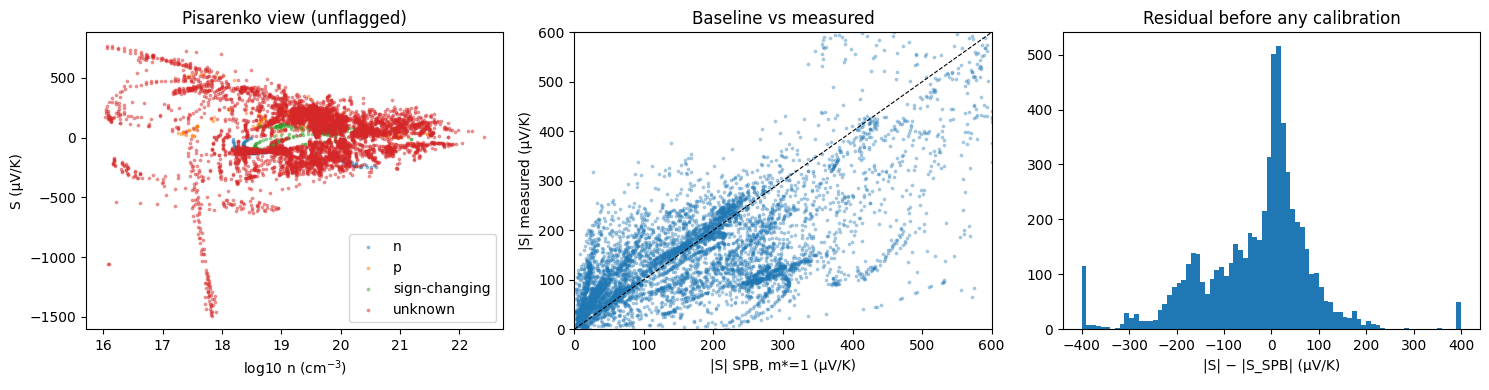

In [20]:
import matplotlib.pyplot as plt
d = m[m.n_flags.eq(0) & m.S_SPB_abs_m1_uVK.notna()]
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for ct, g in d.groupby("carrier_type"):
    ax[0].scatter(g.log10_n_cm3, g.S_uVK, s=3, alpha=.4, label=ct)
ax[0].set(xlabel="log10 n (cm$^{-3}$)", ylabel="S (µV/K)", title="Pisarenko view (unflagged)"); ax[0].legend()
ax[1].scatter(d.S_SPB_abs_m1_uVK, d.S_uVK.abs(), s=3, alpha=.3)
lim = [0, 600]; ax[1].plot(lim, lim, "k--", lw=.8); ax[1].set(xlim=lim, ylim=lim,
    xlabel="|S| SPB, m*=1 (µV/K)", ylabel="|S| measured (µV/K)", title="Baseline vs measured")
ax[2].hist((d.S_uVK.abs() - d.S_SPB_abs_m1_uVK).clip(-400, 400), bins=80)
ax[2].set(xlabel="|S| − |S_SPB| (µV/K)", title="Residual before any calibration")
plt.tight_layout(); plt.show()

In [21]:
# Example: build a feature matrix from the groups (edit to taste)
fg = feature_groups
X_cols = fg["measured_core"] + fg["measured_extra"] + fg["physics_derived"] + fg["composition"]
data = m[m.n_flags.eq(0)]
X, y, groups = data[X_cols], data["S_uVK"], data["study_id"]
print(X.shape, "| missing per column:"); display(X.isna().mean().sort_values(ascending=False).head(10).to_frame("missing"))

(6388, 51) | missing per column:


,missing
kappa_WmK,0.229962
el_n_valence_max,0.054008
el_n_valence_range,0.054008
el_n_valence_mean,0.054008
el_n_valence_min,0.054008
el_n_valence_std,0.054008
log10_sigma_Sm,0.029117
log10_mu_cm2Vs,0.027239
S_SPB_abs_m1_uVK,0.017063
eta_SPB_m1,0.017063


## 16. Save / download

In [22]:
import shutil
shutil.make_archive("seebeck_dataset", "zip", OUT_DIR)
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    dst = Path("/content/drive/MyDrive/seebeck_dataset"); dst.mkdir(parents=True, exist_ok=True)
    for f in OUT_DIR.iterdir(): shutil.copy(f, dst / f.name)
    print("copied to", dst)
try:
    from google.colab import files
    files.download("seebeck_dataset.zip")
except ImportError:
    print("Not on Colab; zip is at seebeck_dataset.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>